In [110]:
!pip install langchain langchain_core langgraph -qqq

### **Quadratic Equation Solving using Conditional Workflow**

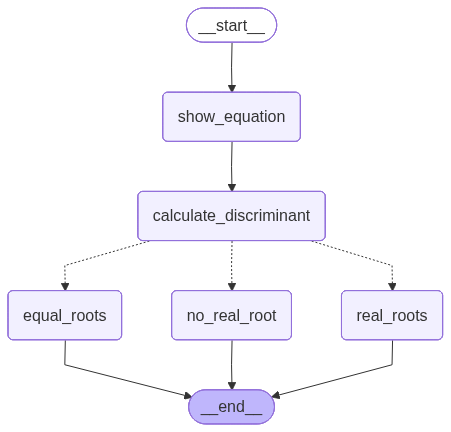

In [129]:
from langgraph.graph import StateGraph,START,END
from typing import TypedDict,Literal

In [123]:
class Quadraticstate(TypedDict):
  a:float
  b:float
  c:float
  d:float
  equation:str
  result:str

In [124]:
def show_equation(state:Quadraticstate):
  a=state['a']
  b=state['b']
  c=state['c']

  eqn=f"{a}x**2 + {b}x + {c}"
  return {'equation':eqn}

def calculate_discriminant(state:Quadraticstate):
  a=state['a']
  b=state['b']
  c=state['c']
  disc=(b**2 - 4*a*c)

  return {'d':disc}

In [140]:
def real_roots(state: Quadraticstate):

    root1 = (-state["b"] + state["d"]**0.5)/(2*state["a"])
    root2 = (-state["b"] - state["d"]**0.5)/(2*state["a"])

    result = f'The roots are {root1} and {root2}'

    return {'result': result}

def equal_roots(state: Quadraticstate):

    root = (-state["b"])/(2*state["a"])

    result = f'Only repeating root is {root}'

    return {'result': result}

def no_real_root(state: Quadraticstate):

    result = f'No real roots'

    return {'result': result}

In [141]:
def check_condition(state:Quadraticstate)->Literal['real_roots','no_real_root','equal_roots']:

  if state['d']>0:
    return 'real_roots'
  elif state['d'] ==0:
    return 'equal_roots'
  else:
    return 'no_real_root'

In [142]:
#create graph
graph=StateGraph(Quadraticstate)
#add nodes
graph.add_node('show_equation',show_equation)
graph.add_node('calculate_discriminant',calculate_discriminant)
graph.add_node('real_roots',real_roots)
graph.add_node('equal_roots',equal_roots)
graph.add_node('no_real_root',no_real_root)

#add edges
graph.add_edge(START, 'show_equation')
graph.add_edge('show_equation', 'calculate_discriminant')

graph.add_conditional_edges('calculate_discriminant', check_condition)
graph.add_edge('real_roots', END)
graph.add_edge('equal_roots', END)
graph.add_edge('no_real_root', END)

#Compile graph
workflow=graph.compile()

In [143]:
initial_state = {
    'a': 2,
    'b': 8,
    'c': 2
}

workflow.invoke(initial_state)

{'a': 2,
 'b': 8,
 'c': 2,
 'd': 48,
 'equation': '2x**2 + 8x + 2',
 'result': 'The roots are -0.2679491924311228 and -3.732050807568877'}

### **LLM based Review Handling Conditional Workflow**

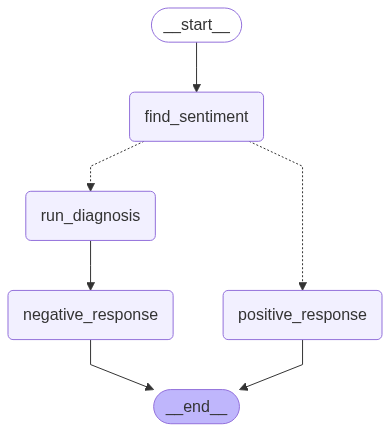

In [145]:
!pip install langchain_openai -qqq

In [149]:
from langgraph.graph import StateGraph,START,END
from pydantic import BaseModel,Field
from typing import TypedDict, Literal,Annotated
from langchain_openai import ChatOpenAI

In [147]:
import os
from google.colab import userdata
os.environ['OPENAI_API_KEY']=userdata.get('OPENAI_API_KEY')

In [148]:
llm=ChatOpenAI(model='gpt-5-nano')

In [150]:
class SentimentSchema(BaseModel):
    sentiment: Literal["positive", "negative"] = Field(description='Sentiment of the review')

In [151]:
class DiagnosisSchema(BaseModel):
    issue_type: Literal["UX", "Performance", "Bug", "Support", "Other"] = Field(description='The category of issue mentioned in the review')
    tone: Literal["angry", "frustrated", "disappointed", "calm"] = Field(description='The emotional tone expressed by the user')
    urgency: Literal["low", "medium", "high"] = Field(description='How urgent or critical the issue appears to be')

In [152]:
structured_llm = llm.with_structured_output(SentimentSchema)
structured_llm2 = llm.with_structured_output(DiagnosisSchema)

In [154]:
prompt = 'What is the sentiment of the following review - The software too good'
structured_llm.invoke(prompt).sentiment

'positive'

In [155]:
class ReviewState(TypedDict):

    review: str
    sentiment: Literal["positive", "negative"]
    diagnosis: dict
    response: str

In [156]:
def find_sentiment(state: ReviewState):

    prompt = f'For the following review find out the sentiment \n {state["review"]}'
    sentiment = structured_llm.invoke(prompt).sentiment

    return {'sentiment': sentiment}

##condition
def check_sentiment(state: ReviewState) -> Literal["positive_response", "run_diagnosis"]:

    if state['sentiment'] == 'positive':
        return 'positive_response'
    else:
        return 'run_diagnosis'


def positive_response(state: ReviewState):

    prompt = f"""Write a warm thank-you message in response to this review:
    \n\n\"{state['review']}\"\n
Also, kindly ask the user to leave feedback on our website."""

    response = llm.invoke(prompt).content

    return {'response': response}


def run_diagnosis(state: ReviewState):

    prompt = f"""Diagnose this negative review:\n\n{state['review']}\n"
    "Return issue_type, tone, and urgency.
"""
    response = structured_llm2.invoke(prompt)

    return {'diagnosis': response.model_dump()}


def negative_response(state: ReviewState):

    diagnosis = state['diagnosis']

    prompt = f"""You are a support assistant.
The user had a '{diagnosis['issue_type']}' issue, sounded '{diagnosis['tone']}', and marked urgency as '{diagnosis['urgency']}'.
Write an empathetic, helpful resolution message.
"""
    response = llm.invoke(prompt).content

    return {'response': response}

In [158]:
#define graph
graph=StateGraph(ReviewState)
#make node
graph.add_node('find_sentiment',find_sentiment)
graph.add_node('run_diagnosis',run_diagnosis)
graph.add_node('negative_response',negative_response)
graph.add_node('positive_response',positive_response)

#make edge
graph.add_edge(START,'find_sentiment')
graph.add_conditional_edges('find_sentiment',check_sentiment)
graph.add_edge('positive_response', END)

graph.add_edge('run_diagnosis', 'negative_response')
graph.add_edge('negative_response', END)


#compile graph
workflow=graph.compile()

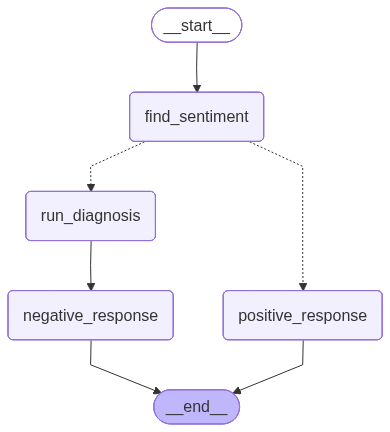

In [159]:
workflow

In [160]:
intial_state={
    'review': "I’ve been trying to log in for over an hour now, and the app keeps freezing on the authentication screen. I even tried reinstalling it, but no luck. This kind of bug is unacceptable, especially when it affects basic functionality."
}
workflow.invoke(intial_state)

{'review': 'I’ve been trying to log in for over an hour now, and the app keeps freezing on the authentication screen. I even tried reinstalling it, but no luck. This kind of bug is unacceptable, especially when it affects basic functionality.',
 'sentiment': 'negative',
 'diagnosis': {'issue_type': 'Bug', 'tone': 'frustrated', 'urgency': 'high'},
 'response': 'Hi there,\n\nI’m really sorry you’re running into this bug, and I understand how frustrating and disruptive it can be—especially with the urgency you’ve flagged. We’re treating this as a high-priority issue and have escalated it to our engineering team right away. A dedicated specialist is on your case, and we’ll keep you updated as we make progress.\n\nWhat we’re doing now\n- Escalating to engineering as a top priority and assigning a point of contact to your issue\n- Investigating the root cause and working toward a fix\n- Collecting the details we need to reproduce and resolve the issue quickly\n\nWhat we need from you to spee